# PSet #3 — Notebook 04: Tuning de hiperparámetros

Se ajustan los **3 mejores candidatos** del notebook 03: Logística, HistGradientBoosting y SVC. **30 configuraciones por modelo**, 5 folds estratificados y **90 corridas hijas** en MLflow, una por configuración.

- Fuente: `PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT` con un solo snapshot transversal.
- Split **exactamente igual** al de `03_baseline_candidatos.ipynb`: 80 % train / 20 % hold-out reservado; semilla 42.
- **No se utiliza el hold-out para ninguna selección ni tuning**.
- Preprocesamiento y features dentro de `src/pipeline.py`; se reajustan dentro de cada fold.
- Búsqueda `RandomizedSearchCV` con `average_precision`; solo se registran resultados efectivamente calculados.
- Al terminar: comparar la mejora con la variabilidad entre folds. Un cambio pequeño NO demuestra superioridad.

**Atención:** el notebook entrena 450 modelos para CV (3 × 30 × 5), además de reentrenar cada configuración para guardar sus artefactos. Ejecutar las tres celdas de entrenamiento en orden. No cerrar Jupyter mientras se guardan artefactos.


In [1]:
from pathlib import Path
import json, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
import mlflow
from src.datos import leer_obt, variables_modelo, hash_snapshot, ORIGEN
from src.tuning import ajustar_y_registrar, definiciones_modelos, EXPERIMENTO, SEED

OUT = Path('/workspace/docs')
OUT.mkdir(parents=True, exist_ok=True)
TRACKING = os.environ.get('MLFLOW_TRACKING_URI', 'http://mlflow:5000')
mlflow.set_tracking_uri(TRACKING)
print('Tracking:', TRACKING)


Tracking: http://mlflow:5000


## A. Recuperar exactamente el split del notebook 03

El hash y el manifiesto de clientes deben coincidir. Esta comprobación protege contra una nueva descarga con contenido diferente y contra la utilización accidental del hold-out.

In [2]:
df = leer_obt().sort_values('CUSTOMER_ID', kind='stable').reset_index(drop=True)
X, y = variables_modelo(df)
info = json.loads((OUT/'split_info.json').read_text(encoding='utf-8'))
assert info['hash_dataset'] == hash_snapshot(df), 'La OBT cambió desde el notebook 03: detener y revisar'
assert info['origen'] == ORIGEN
assert int(info['seed']) == SEED
idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEED, stratify=y
)
idx_train, idx_test = np.sort(idx_train), np.sort(idx_test)
manifest = pd.read_csv(OUT/'split_train_test.csv', dtype={'CUSTOMER_ID':str})
assert manifest['CUSTOMER_ID'].tolist() == df['CUSTOMER_ID'].astype(str).tolist()
assert set(manifest.loc[idx_train, 'split']) == {'train'}
assert set(manifest.loc[idx_test, 'split']) == {'test'}
X_train, y_train = X.iloc[idx_train].copy(), y.iloc[idx_train].copy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))
assert len(X_train) == 5634 and len(idx_test) == 1409
assert 'CUSTOMER_ID' not in X_train and 'INGESTED_AT' not in X_train and 'CHURN_FLAG' not in X_train
candidatos = pd.read_csv(OUT/'resultados_candidatos.csv')
top = candidatos.query("fase=='candidato'").sort_values('cv_ap_mean',ascending=False).head(3)['nombre'].tolist()
esperados = ['Candidato_Logistica','Candidato_HistGradientBoosting','Candidato_SVC']
assert top == esperados, f'Ranking cambió: {top}. Revisar antes de seguir.'
print('Hash de snapshot:',info['hash_dataset'])
print('Train:',len(X_train),'| Test SOLO reservado:',len(idx_test),'| Folds:',len(folds))
print('Candidatos seleccionados:',top)
display(candidatos.set_index('nombre').loc[top,['cv_ap_mean','cv_ap_std','gap_ap_train_vs_cv']].round(4))


Hash de snapshot: d394e39192c935f813db937647ea608341131d5b3021696fbbb186daff7043d3
Train: 5634 | Test SOLO reservado: 1409 | Folds: 5
Candidatos seleccionados: ['Candidato_Logistica', 'Candidato_HistGradientBoosting', 'Candidato_SVC']


,cv_ap_mean,cv_ap_std,gap_ap_train_vs_cv
nombre,,,
Candidato_Logistica,0.6531,0.0116,0.0074
Candidato_HistGradientBoosting,0.6413,0.0283,0.2189
Candidato_SVC,0.6342,0.0166,0.0688


## B. Tuning — Regresión logística

Rangos logarítmicos para `C` y tolerancia; penalización L2 por defecto; peso de clases en {normal, balanceado}. Cualquier reducción de varianza o mejora en AP se medirá frente a la versión sin tuning.

In [3]:
r_logistica = ajustar_y_registrar(
    'Candidato_Logistica', X_train, y_train, folds,
    info, candidatos, out_dir=OUT, guardar_modelos_hijos=True
)
(OUT/'tuning_resumen_Candidato_Logistica.json').write_text(
    json.dumps(r_logistica, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Logística finalizada y guardada (30 corridas hijas).')


Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_Logistica_config_01 at: http://mlflow:5000/#/experiments/1/runs/e9c6497ba0c445b38538ead6d0767dcc
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_Logistica_config_02 at: http://mlflow:5000/#/experiments/1/runs/964067effe5744d88a94b5bee721a50e
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


... (53 outputs left out)

/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_Logistica_config_30 at: http://mlflow:5000/#/experiments/1/runs/fd98911bd12e4f359a815726cce2d48f
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Tuning_Candidato_Logistica at: http://mlflow:5000/#/experiments/1/runs/53e27c5f9ccf4f12bd30d0c3405a8b42
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Candidato_Logistica: 30 configs | AP 0.6531 -> 0.6538 (mejora +0.0007; sd=0.0113).
  ¿Mejora mayor que variación entre folds? False
Logística finalizada y guardada (30 corridas hijas).


## C. Tuning — HistGradientBoosting

Se controla complejidad del boosting mediante profundidad, hojas, regularización L2, cantidad de iteraciones y tasa de aprendizaje. En el notebook 03 este candidato mostró una brecha grande entre entrenamiento y CV.

In [4]:
r_hgb = ajustar_y_registrar(
    'Candidato_HistGradientBoosting', X_train, y_train, folds,
    info, candidatos, out_dir=OUT, guardar_modelos_hijos=True
)
(OUT/'tuning_resumen_Candidato_HistGradientBoosting.json').write_text(
    json.dumps(r_hgb, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('HistGradientBoosting finalizado y guardado (30 corridas hijas).')


Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_HistGradientBoosting_config_01 at: http://mlflow:5000/#/experiments/1/runs/50549f4d61c141b485a92e0b478759be
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_HistGradientBoosting_config_02 at: http://mlflow:5000/#/experiments/1/runs/b373b9094b9443bfbd5b5067a81c3be5
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


... (53 outputs left out)

/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Candidato_HistGradientBoosting_config_30 at: http://mlflow:5000/#/experiments/1/runs/5dd6d7b57b7e43f4bd5a409fa3f0b0f0
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Tuning_Candidato_HistGradientBoosting at: http://mlflow:5000/#/experiments/1/runs/bede0749c3594277b1dc3eced16057e6
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Candidato_HistGradientBoosting: 30 configs | AP 0.6413 -> 0.6691 (mejora +0.0278; sd=0.0172).
  ¿Mejora mayor que variación entre folds? False
HistGradientBoosting finalizado y guardado (30 corridas hijas).


## D. Tuning — SVC (kernel RBF)

Se ajustan `C`, `gamma` y `class_weight`. Se conserva `probability=True` para que el modelo sea útil en la fase de umbrales y costos del notebook 05.

In [5]:
r_svc = ajustar_y_registrar(
    'Candidato_SVC', X_train, y_train, folds,
    info, candidatos, out_dir=OUT, guardar_modelos_hijos=True
)
(OUT/'tuning_resumen_Candidato_SVC.json').write_text(
    json.dumps(r_svc, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('SVC finalizado y guardado (30 corridas hijas).')


Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

🏃 View run Candidato_SVC_config_01 at: http://mlflow:5000/#/experiments/1/runs/b6b25422fedd4ec89deabfd1ebe086fd
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more de

🏃 View run Candidato_SVC_config_02 at: http://mlflow:5000/#/experiments/1/runs/156357cc378c48cba5da559817745f16
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more de

... (53 outputs left out)

/usr/local/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more de

🏃 View run Candidato_SVC_config_30 at: http://mlflow:5000/#/experiments/1/runs/28c32770f67f45128b91ffca44e2635b
🧪 View experiment at: http://mlflow:5000/#/experiments/1


/usr/local/lib/python3.11/site-packages/mlflow/types/utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Tuning_Candidato_SVC at: http://mlflow:5000/#/experiments/1/runs/ef6c4b9e4ce44f36bf98e6b8eecc3f3e
🧪 View experiment at: http://mlflow:5000/#/experiments/1
Candidato_SVC: 30 configs | AP 0.6342 -> 0.6511 (mejora +0.0169; sd=0.0108).
  ¿Mejora mayor que variación entre folds? True
SVC finalizado y guardado (30 corridas hijas).


## E. Comparación final del tuning, sin abrir el conjunto de prueba

La decisión del ganador *definitivo* queda pendiente del notebook 05. Aquí se seleccionan dos finalistas según media y variación de CV. La comparación con la variabilidad entre folds evita declarar mejora por diferencias insignificantes.

,nombre,default_ap,default_std,tuned_ap,tuned_std,mejora_ap,mejora_supera_variabilidad,brecha_train_cv,fit_refit_seconds,num_config
1,Candidato_HistGradientBoosting,0.6413,0.0283,0.6691,0.0172,0.0278,False,0.0444,0.1414,30
0,Candidato_Logistica,0.6531,0.0116,0.6538,0.0113,0.0007,False,0.0084,0.0467,30
2,Candidato_SVC,0.6342,0.0166,0.6511,0.0108,0.0169,True,0.0031,2.5725,30


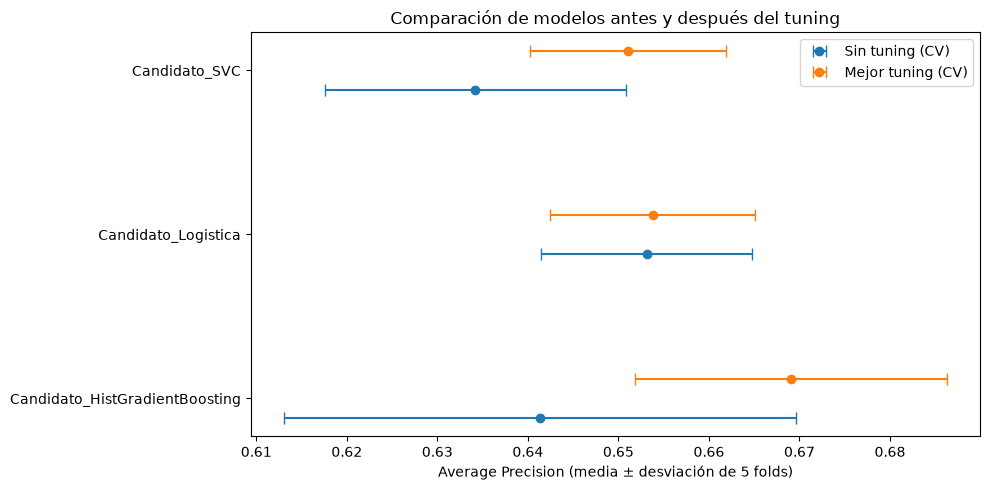

Exportadas 100 corridas a docs/corridas.csv.
Primeros dos candidatos para comparar en TEST (una sola vez, notebook 05):


,nombre,tuned_ap,tuned_std,mejora_ap
1,Candidato_HistGradientBoosting,0.669069,0.017210,0.027757
0,Candidato_Logistica,0.653788,0.011318,0.000683


In [6]:
resumenes = [json.loads((OUT/f'tuning_resumen_{n}.json').read_text(encoding='utf-8'))
            for n in esperados]
resumen = pd.DataFrame(resumenes).sort_values('tuned_ap',ascending=False)
assert len(resumen) == 3 and resumen['num_config'].sum() == 90
resumen.to_csv(OUT/'resultados_tuning.csv',index=False)
display(resumen[['nombre','default_ap','default_std','tuned_ap','tuned_std',
                 'mejora_ap','mejora_supera_variabilidad','brecha_train_cv',
                 'fit_refit_seconds','num_config']].round(4))
fig, ax = plt.subplots(figsize=(10,5))
pos = np.arange(len(resumen))
ax.errorbar(resumen['default_ap'], pos-.12, xerr=resumen['default_std'],
            fmt='o', capsize=4, label='Sin tuning (CV)')
ax.errorbar(resumen['tuned_ap'], pos+.12, xerr=resumen['tuned_std'],
            fmt='o', capsize=4, label='Mejor tuning (CV)')
ax.set_yticks(pos, resumen['nombre'])
ax.set_xlabel('Average Precision (media ± desviación de 5 folds)')
ax.set_title('Comparación de modelos antes y después del tuning')
ax.legend()
plt.tight_layout()
plt.savefig(OUT/'tuning_comparacion.png',dpi=160)
plt.show()

runs = mlflow.search_runs(experiment_names=[EXPERIMENTO], output_format='pandas')
runs.to_csv(OUT/'corridas.csv', index=False)
print('Exportadas',len(runs),'corridas a docs/corridas.csv.')
print('Primeros dos candidatos para comparar en TEST (una sola vez, notebook 05):')
display(resumen[['nombre','tuned_ap','tuned_std','mejora_ap']].head(2))


## F. Siguiente etapa — Notebook 05

1. Leer `docs/resultados_tuning.csv` y las corridas MLflow.
2. Considerar la incertidumbre de CV, la complejidad y la explicabilidad.
3. **Evaluar por primera y única vez el hold-out** con los dos finalistas.
4. Ajustar el umbral sobre predicciones de CV en entrenamiento y costos **hipotéticos**; no seleccionar umbral mirando el hold-out.
5. Registrar el ganador como `PSet3_Churn_Telco-modelo` con alias `champion`, segundo `challenger`.
6. Abrir el `champion` desde el Model Registry y verificar reproducibilidad.

**Límites:** esta OBT no contiene seguimiento temporal ni costos reales de retención. El trabajo mide calidad de clasificación, no impacto causal de campañas.
